### EXPLORING SEAGLIDER SG267 AD2CP DATA

This notebook reads all the dive files (`p267dddd.nc`, one file per dive) and builds 2D arrays
(depth x time) of ocean velocity, so we can look at how the currents change over the whole mission.

It uses the **ocean velocities** (`ad2cp_inv_profile_uocn`, `ad2cp_inv_profile_vocn`): the processed product
from the inverse solution, i.e. true eastward/northward ocean currents on a 5 m depth grid.

The heavy lifting (reading the files) lives in `adcp_gridding.py` in this folder.

Processing steps here: https://github.com/iop-apl-uw/ad2cp_python/blob/master/docs/Seaglider_ADCP_processing.pdf

#### SETUP THE FUNCTIONS AND PATHS

In [ ]:
import os

import xarray as xr               # reading NetCDF files and labelled arrays
import matplotlib.pyplot as plt   # plotting

# Our own helper functions (see adcp_gridding.py)
from adcp_gridding import load_inv_profiles

In [ ]:
# Folder that contains all the dive files (p2670001.nc, p2670002.nc, ...)
path_to_files = "../data/sg267/"

# Reading ~470 files from Google Drive takes several minutes, so the result is saved
# ("cached") to this file the first time. Next time it is simply re-opened.
# Delete the cache file if the raw data changes and you want it rebuilt.
inv_cache_file = "../data/sg267_adcp_inv_profiles.nc"

#### OCEAN VELOCITIES (`ad2cp_inv_profile_uocn`, `ad2cp_inv_profile_vocn`)

These are processed onto a depth grid (0-1000 m every 5 m) in each file, with two profiles
per dive: index 0 = descent, 1 = ascent. 

No binning is needed: we just put the profiles side by side
in time order. `uocn` is eastward and `vocn` is northward velocity.

Only dives 1-244 contain these profiles; later files are skipped.

In [12]:
if os.path.exists(inv_cache_file):
    # Fast path: re-use the previously saved result
    ds_ocn = xr.open_dataset(inv_cache_file).load()
else:
    # Slow path: read the inverse profiles from every file
    ds_ocn = load_inv_profiles(path_to_files)
    ds_ocn.to_netcdf(inv_cache_file)

# Show a summary: dimensions are (depth, time); 'dive' and 'cast' tell you where each column came from
ds_ocn

<xarray.Dataset> Size: 797kB
Dimensions:                 (depth: 201, time: 488)
Coordinates:
  * depth                   (depth) float32 804B 0.0 5.0 10.0 ... 995.0 1e+03
  * time                    (time) datetime64[ns] 4kB 2026-07-17T08:42:43.499...
    dive                    (time) int64 4kB 1 1 2 2 3 3 ... 242 243 243 244 244
    cast                    (time) int64 4kB 0 1 0 1 0 1 0 1 ... 0 1 0 1 0 1 0 1
Data variables:
    ad2cp_inv_profile_uocn  (depth, time) float32 392kB 0.297 0.099 ... nan nan
    ad2cp_inv_profile_vocn  (depth, time) float32 392kB 0.417 0.337 ... nan nan

In [13]:
# 2D arrays of shape (depth, time): one column per descent / ascent
uocn = ds_ocn['ad2cp_inv_profile_uocn']  # eastward ocean velocity (m/s)
vocn = ds_ocn['ad2cp_inv_profile_vocn']  # northward ocean velocity (m/s)

uocn.shape

(201, 488)

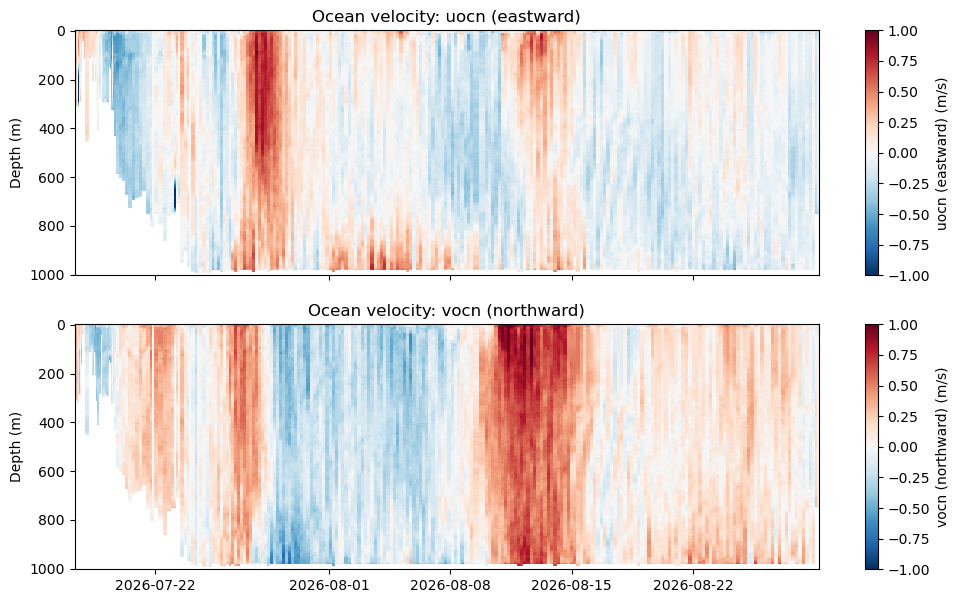

In [15]:
# Plot the ocean velocity as a function of time (x) and depth (y)
fig, axs = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for ax, v, name in zip(axs, [uocn, vocn], ['uocn (eastward)', 'vocn (northward)']):
    pc = ax.pcolormesh(ds_ocn['time'], ds_ocn['depth'], v, cmap='RdBu_r', vmin=-1, vmax=1)
    fig.colorbar(pc, ax=ax, label=f'{name} (m/s)')
    ax.set_ylabel('Depth (m)')
    ax.invert_yaxis()  # so the surface is at the top
    ax.set_title(f'Ocean velocity: {name}')
plt.show()